# 01 - EDA

Train only. Figures go to `images/`.

In [1]:
import sys

sys.path.insert(0, "../src")

In [2]:
import os

os.environ["TRANSFORMERS_VERBOSITY"] = "error"   # silence "PyTorch not found" / long-sequence warnings
import re
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from transformers import AutoTokenizer

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED

pd.set_option("display.width", 140)
COLORS = {"human": "tab:blue", "ai": "tab:red", "fusion": "tab:green"}

## Config

In [3]:
N_SAMPLE = 50_000   # stratified sample for the heavier per-text statistics and n-gram counts
TOKENIZER = "xlm-roberta-base"   # used only to count tokens
IMG_DIR = "../images"
os.makedirs(IMG_DIR, exist_ok=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(IMG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

## Load data

In [4]:
train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")
LANG_COL = common.lang_col(train_df)
DOMAIN_COL = next((c for c in ["domain", "source", "genre", "category"] if c in train_df.columns), None)

assert set(train_df[LABEL_COL].unique()) == set(LABELS), train_df[LABEL_COL].unique()
print("train:", train_df.shape, "| test:", test_df.shape)
print("train columns:", list(train_df.columns), "| test columns:", list(test_df.columns))
print("language column:", LANG_COL, "| domain column:", DOMAIN_COL)
train_df.head(3)

train: (272352, 5) | test: (25000, 4)
train columns: ['id', 'text', 'lang', 'domain', 'label'] | test columns: ['id', 'text', 'lang', 'domain']
language column: lang | domain column: domain


,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend ...,en-EN,cnn_news,ai
1,3bab63,Herr Präsident! Meine Damen und Herren! Es wir...,de-DE,bundestag,human
2,4e6c1f,Frau Präsidentin! Liebe Kolleginnen und Kolleg...,de-DE,bundestag,human


In [5]:
# data quality: missing / empty texts, exact duplicates, train-test text overlap
txt = train_df[TEXT_COL].fillna("").astype(str)
dup_mask = txt.duplicated(keep=False)
conflict = (train_df[dup_mask].assign(t=txt[dup_mask]).groupby("t")[LABEL_COL].nunique() > 1).sum()
overlap = test_df[TEXT_COL].fillna("").astype(str).isin(set(txt)).sum()
pd.Series({
    "missing text (train)": train_df[TEXT_COL].isna().sum(),
    "empty / whitespace text (train)": (txt.str.strip() == "").sum(),
    "rows with duplicated text (train)": dup_mask.sum(),
    "duplicated texts with conflicting labels": conflict,
    "test texts also present in train": overlap,
}).to_frame("count")

,count
missing text (train),0
empty / whitespace text (train),0
rows with duplicated text (train),0
duplicated texts with conflicting labels,0
test texts also present in train,0


## Class balance: overall, by language, by domain

In [6]:
overall = train_df[LABEL_COL].value_counts().reindex(LABELS)
pd.DataFrame({"n": overall, "share": (overall / overall.sum()).round(3)})

,n,share
label,,
human,66730,0.245
ai,121940,0.448
fusion,83682,0.307


In [7]:
def balance(col):
    counts = pd.crosstab(train_df[col], train_df[LABEL_COL]).reindex(columns=LABELS)
    counts["total"] = counts.sum(axis=1)
    shares = counts[LABELS].div(counts["total"], axis=0).round(3).add_suffix(" %")
    return pd.concat([counts, shares], axis=1).sort_values("total", ascending=False)


balance(LANG_COL) if LANG_COL else "no language column"

label,human,ai,fusion,total,human %,ai %,fusion %
lang,,,,,,,
en-EN,52220,101603,65758,219581,0.238,0.463,0.299
de-DE,14510,20337,17924,52771,0.275,0.385,0.340


In [8]:
balance(DOMAIN_COL) if DOMAIN_COL else "no domain column"

label,human,ai,fusion,total,human %,ai %,fusion %
domain,,,,,,,
student_essays,12506,21583,20017,54106,0.231,0.399,0.370
bundestag,14479,19977,17887,52343,0.277,0.382,0.342
cnn_news,13395,19488,11402,44285,0.302,0.440,0.257
blog_authorship_corpus,12466,15684,12397,40547,0.307,0.387,0.306
house_of_commons,6953,15298,9608,31859,0.218,0.480,0.302
euro_court_cases,6277,11141,10160,27578,0.228,0.404,0.368
arxiv_papers,407,12050,1833,14290,0.028,0.843,0.128
gutenberg,247,6719,378,7344,0.034,0.915,0.051


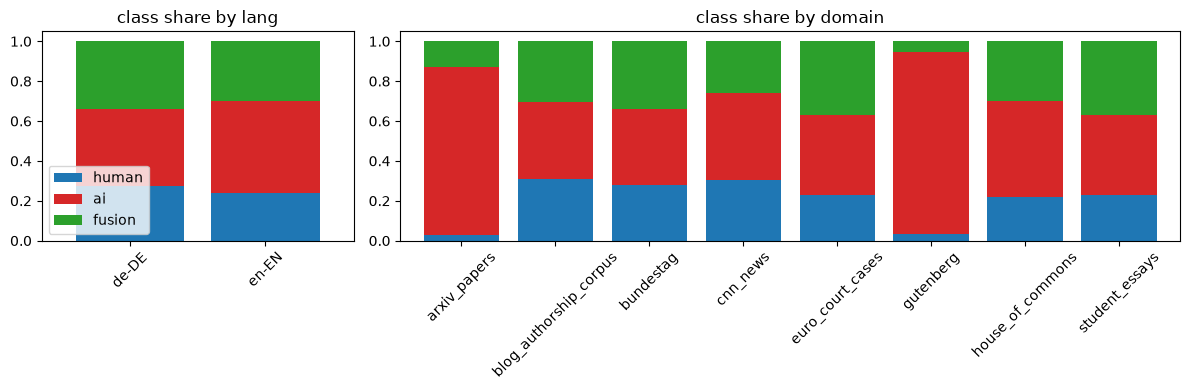

In [9]:
# share of each class per group (stacked bars): is the label distribution the same everywhere?
groups = [c for c in [LANG_COL, DOMAIN_COL] if c]
if groups:
    fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4), squeeze=False,
                             gridspec_kw={"width_ratios": [train_df[c].nunique() + 2 for c in groups]})
    for ax, col in zip(axes[0], groups):
        pd.crosstab(train_df[col], train_df[LABEL_COL], normalize="index")[LABELS].plot(
            kind="bar", stacked=True, ax=ax, color=[COLORS[l] for l in LABELS], width=0.8, legend=False)
        ax.set_title(f"class share by {col}")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
    axes[0][0].legend(LABELS, loc="lower left")
    savefig("eda_balance.png")

In [10]:
# language x domain cell sizes (if both exist): are some domains present in one language only?
pd.crosstab(train_df[DOMAIN_COL], train_df[LANG_COL]) if LANG_COL and DOMAIN_COL else None

lang,de-DE,en-EN
domain,,
arxiv_papers,0,14290
blog_authorship_corpus,0,40547
bundestag,52343,0
cnn_news,0,44285
euro_court_cases,0,27578
gutenberg,428,6916
house_of_commons,0,31859
student_essays,0,54106


In [11]:
# does the test set look like train? (language / domain shares)
for col in groups:
    if col in test_df.columns:
        display(pd.DataFrame({"train": train_df[col].value_counts(normalize=True),
                              "test": test_df[col].value_counts(normalize=True)}).round(3))

,train,test
lang,,
en-EN,0.806,0.853
de-DE,0.194,0.147


,train,test
domain,,
arxiv_papers,0.052,0.067
blog_authorship_corpus,0.149,0.178
bundestag,0.192,0.143
cnn_news,0.163,0.197
euro_court_cases,0.101,0.064
gutenberg,0.027,0.074
house_of_commons,0.117,0.118
student_essays,0.199,0.159


## Text lengths

- Transformer input: 512 tokens -> longer texts get truncated
- Token counts: real `TOKENIZER` on the sample, no estimate

In [12]:
sample = common.subsample(train_df, N_SAMPLE).copy()
s_txt = sample[TEXT_COL].fillna("").astype(str)
sample["n_chars"] = s_txt.str.len()
sample["n_words"] = s_txt.str.split().str.len()

tok = AutoTokenizer.from_pretrained(TOKENIZER)
sample["n_tokens"] = [len(ids) for ids in tok(s_txt.tolist(), add_special_tokens=False)["input_ids"]]

train_df["n_chars"] = train_df[TEXT_COL].fillna("").astype(str).str.len()
by = [LANG_COL, LABEL_COL] if LANG_COL else [LABEL_COL]
(train_df.groupby(by)["n_chars"].describe(percentiles=[0.05, 0.5, 0.95])
 .drop(columns=["count", "std"]).round(0))

mean    min      5%     50%      95%      max
lang  label                                                  
de-DE ai      3065.0  121.0   628.0  3106.0   5090.0  20069.0
      fusion  4302.0  137.0  1780.0  4098.0   7235.0  22138.0
      human   4073.0  117.0   632.0  4060.0   7320.0  20543.0
en-EN ai      3330.0   87.0   329.0  3115.0   7089.0  22646.0
      fusion  3455.0   92.0   383.0  2313.0  12286.0  34876.0
      human   3331.0   76.0   286.0  2498.0   9554.0  21376.0

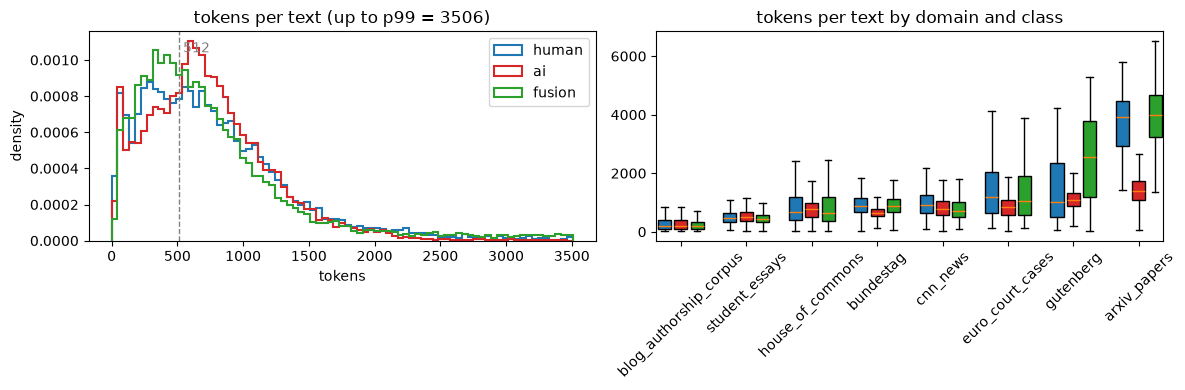

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p99 = sample["n_tokens"].quantile(0.99)
bins = np.linspace(0, p99, 80)   # texts above p99 are not shown
for lab in LABELS:
    axes[0].hist(sample.loc[sample[LABEL_COL] == lab, "n_tokens"], bins=bins, histtype="step",
                 density=True, lw=1.5, color=COLORS[lab], label=lab)
axes[0].axvline(512, ls="--", c="gray", lw=1)
axes[0].text(512, axes[0].get_ylim()[1] * 0.9, " 512", color="gray")
axes[0].set(title=f"tokens per text (up to p99 = {p99:.0f})", xlabel="tokens", ylabel="density")
axes[0].legend()

if DOMAIN_COL:
    order = sample.groupby(DOMAIN_COL)["n_tokens"].median().sort_values().index
    data = [sample.loc[(sample[DOMAIN_COL] == d) & (sample[LABEL_COL] == lab), "n_tokens"]
            for d in order for lab in LABELS]
    pos = [i * 4 + j for i in range(len(order)) for j in range(3)]
    bp = axes[1].boxplot(data, positions=pos, widths=0.8, showfliers=False, patch_artist=True)
    for patch, k in zip(bp["boxes"], range(len(data))):
        patch.set_facecolor(COLORS[LABELS[k % 3]])
    axes[1].set_xticks([i * 4 + 1 for i in range(len(order))], order, rotation=45)
    axes[1].set(title="tokens per text by domain and class")
else:
    axes[1].boxplot([sample.loc[sample[LABEL_COL] == l, "n_tokens"] for l in LABELS], showfliers=False)
    axes[1].set_xticks([1, 2, 3], LABELS)
    axes[1].set(title="tokens per text by class")
savefig("eda_lengths.png")

In [14]:
# share of texts longer than 512 tokens, and tokens per word (differs between languages)
sample["over_512_tok"] = sample["n_tokens"] > 512
sample["tok_per_word"] = sample["n_tokens"] / sample["n_words"].clip(lower=1)
sample.groupby(by)[["over_512_tok", "tok_per_word"]].mean().round(3)

over_512_tok  tok_per_word
lang  label                             
de-DE ai             0.765         1.514
      fusion         0.915         1.513
      human          0.842         1.520
en-EN ai             0.656         1.487
      fusion         0.506         1.376
      human          0.568         1.367

In [15]:
# overall share over 512 tokens and median tokens per domain and class
print(f"texts over 512 tokens (all): {sample['over_512_tok'].mean():.3f}")
(sample.groupby([DOMAIN_COL, LABEL_COL])["n_tokens"].median().unstack()[LABELS].round(0)
 if DOMAIN_COL else None)

texts over 512 tokens (all): 0.639


label,human,ai,fusion
domain,,,
arxiv_papers,3932.0,1383.0,3985.0
blog_authorship_corpus,198.0,194.0,185.0
bundestag,895.0,646.0,885.0
cnn_news,904.0,789.0,711.0
euro_court_cases,1174.0,861.0,1064.0
gutenberg,1013.0,1087.0,2569.0
house_of_commons,683.0,784.0,651.0
student_essays,480.0,513.0,443.0


## Style statistics

| Feature | Meaning |
|---|---|
| `type_token_ratio` | lexical diversity (first 300 words) |
| `mean_word_len`, `mean_sent_len` | word / sentence length |
| `sent_len_cv` | sentence-length variation ("burstiness") |
| `punct_per_100c`, `uppercase_ratio`, `digit_ratio`, `non_ascii_ratio` | character mix |
| `newlines_per_100w` | formatting |

- Statistic: median per class, on the stratified sample (`N_SAMPLE`)

In [16]:
from features import style_features   # src/features.py

style = pd.DataFrame([style_features(t) for t in s_txt], index=sample.index)
STYLE_COLS = list(style.columns)
sample = pd.concat([sample, style], axis=1)
sample.groupby(LABEL_COL)[STYLE_COLS].median().reindex(LABELS).T.round(3)

label,human,ai,fusion
type_token_ratio,0.567,0.617,0.590
mean_word_len,4.649,5.372,4.872
mean_sent_len,17.533,18.191,17.333
sent_len_cv,0.618,0.436,0.576
punct_per_100c,1.353,1.367,1.244
uppercase_ratio,0.030,0.021,0.026
digit_ratio,0.003,0.000,0.002
newlines_per_100w,0.000,0.000,0.000
non_ascii_ratio,0.000,0.002,0.000


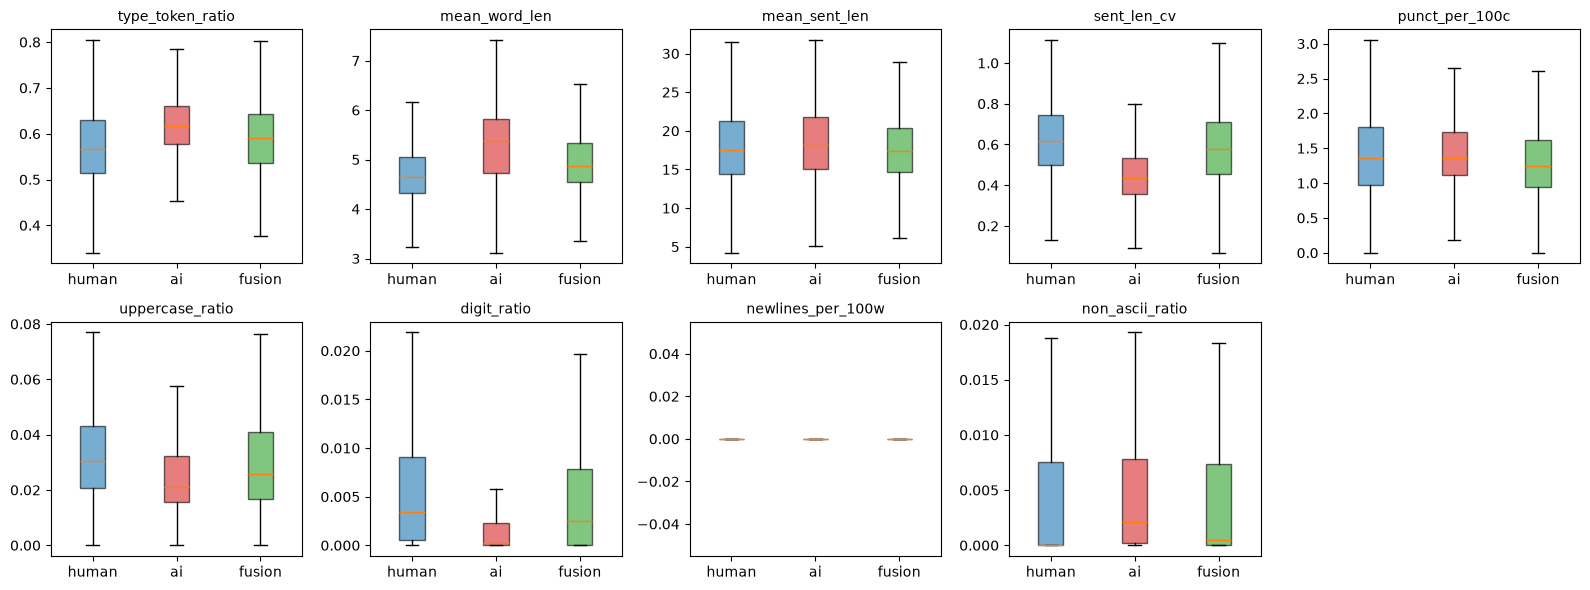

In [17]:
fig, axes = plt.subplots(2, (len(STYLE_COLS) + 1) // 2, figsize=(16, 6))
for ax, col in zip(axes.ravel(), STYLE_COLS):
    ax.boxplot([sample.loc[sample[LABEL_COL] == l, col] for l in LABELS], showfliers=False,
               patch_artist=True, boxprops=dict(alpha=0.6))
    for patch, l in zip(ax.patches, LABELS):
        patch.set_facecolor(COLORS[l])
    ax.set_xticks([1, 2, 3], LABELS)
    ax.set_title(col, fontsize=10)
for ax in axes.ravel()[len(STYLE_COLS):]:
    ax.axis("off")
savefig("eda_style.png")

In [18]:
# where is the fusion between human and ai? 0 = like human, 1 = like ai (per language, medians)
def fusion_position(df):
    m = df.groupby(LABEL_COL)[STYLE_COLS + ["n_words"]].median()
    gap = (m.loc["ai"] - m.loc["human"]).replace(0, np.nan)
    return ((m.loc["fusion"] - m.loc["human"]) / gap).round(2)


if LANG_COL:
    display(pd.DataFrame({lang: fusion_position(g) for lang, g in sample.groupby(LANG_COL)}))
else:
    display(fusion_position(sample).to_frame("all"))

,de-DE,en-EN
type_token_ratio,0.00,0.40
mean_word_len,0.32,0.32
mean_sent_len,0.12,-1.37
sent_len_cv,0.26,0.21
punct_per_100c,0.46,-0.72
uppercase_ratio,0.60,0.64
digit_ratio,0.28,0.28
newlines_per_100w,NaN,NaN
non_ascii_ratio,0.74,0.00
n_words,0.03,-1.62


## Examples of each class

In [19]:
def show_examples(n_per_group=1, width=110, max_chars=400):
    keys = [LANG_COL, LABEL_COL] if LANG_COL else [LABEL_COL]
    for key, g in sample.groupby(keys):
        for _, row in g.sample(n_per_group, random_state=SEED).iterrows():
            meta = f"{key} | domain={row[DOMAIN_COL]}" if DOMAIN_COL else str(key)
            body = row[TEXT_COL][:max_chars].replace("\n", " / ")
            print(f"--- {meta} | {row['n_words']} words")
            print(textwrap.fill(body, width) + (" ..." if len(row[TEXT_COL]) > max_chars else ""), "\n")


show_examples()

--- ('de-DE', 'ai') | domain=bundestag | 328 words
Die Situation in Israel und den besetzten Gebieten ist seit langem ein zentrales Anliegen der deutschen
Außenpolitik. Die internationale Gemeinschaft blickt mit Besorgnis auf die jüngsten Entwicklungen, vor allem
auf die Pläne des neuen israelischen Governments für territoriale Annexionen. Wir stehen für eine friedliche
Lösung des Konflikts und sind überzeugt, dass die Zwei-Staaten-Lösung, ein jüd ... 

--- ('de-DE', 'fusion') | domain=bundestag | 623 words
Sehr geehrte Frau Präsidentin! Meine Damen und Herren! Die Diskussion über eine der größten Sozialreformen der
letzten Jahrzehnte, nämlich das Bürgergeld, ist eine sehr wichtige, und sie wird sehr kontrovers geführt.
Meine Damen und Herren, lassen Sie uns zunächst die Grundlagen des Bürgergeldes betrachten. Meine Damen und
Herren, wer keine Argumente in der Sache hat, verliert sich im Verfahren, u ... 

--- ('de-DE', 'human') | domain=bundestag | 540 words
Vielen Dank. – Herr Präsid

In [20]:
# fusion texts: the start and the end of the same text, to see whether the rewritten part is localised
for _, row in sample[sample[LABEL_COL] == "fusion"].sample(2, random_state=SEED + 1).iterrows():
    t = row[TEXT_COL].replace("\n", " / ")
    print(f"--- fusion | {row['n_words']} words\nSTART: {textwrap.shorten(t[:300], 300)}\n"
          f"END:   {textwrap.shorten(t[-300:], 300)}\n")

--- fusion | 180 words
START: I think the Face On Mars is a natural landform because there are other landforms already like it on Earth, and there are other mesas like it around the Cydonia region. I think if aliens were on Mars I think we might have discovered them by now, but you can never be sure. The Face is just formed by c
END:   ems illogical because in 2001 they went back to the face and took more pictures with even higher resolution and found that there were no markings at all, meaning more evidence leaning towards the Face just being a natural landmass and not an alien artifact. It was just a mesa the whole time. Besides

--- fusion | 353 words
START: What I think about driveless cars is that it could be benifitual to the everyday workaholic but not the someone who doesnt plan their day. There are positive things to having driveless cars and their are negitives things too. One of the most significant advantages of driveless cars is their potentia
END:   rash on a freeway? wou

## Distinctive words per class

- Method: smoothed log-odds of word frequencies, one class vs the rest
- Data: stratified sample, per language
- Top words = most typical for the class

In [21]:
def top_log_odds(df, k=15, min_df=20):
    cv = CountVectorizer(lowercase=True, min_df=min_df, token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
    X = cv.fit_transform(df[TEXT_COL].fillna(""))
    vocab = np.array(cv.get_feature_names_out())
    y = df[LABEL_COL].values
    out = {}
    for lab in LABELS:
        a = np.asarray(X[y == lab].sum(0)).ravel() + 1
        b = np.asarray(X[y != lab].sum(0)).ravel() + 1
        lo = np.log(a / a.sum()) - np.log(b / b.sum())
        out[lab] = vocab[np.argsort(-lo)[:k]]
    return pd.DataFrame(out)


for lang, g in (sample.groupby(LANG_COL) if LANG_COL else [("all", sample)]):
    print(f"language: {lang}")
    display(top_log_odds(g))

language: de-DE


,human,ai,fusion
0,enthaltungen,honorable,kernbotschaft
1,gänze,where,fachkraft
2,bekomme,their,furchtbar
3,aufsetzen,stehe,südens
4,rettungsschirm,through,end
5,herzlichen,seelen,sicherheitskonferenz
6,polizistinnen,between,entsetzt
7,staatsministerin,economic,unanständig
8,ausgewiesen,that,schafe
9,gestattet,its,gebäudesanierung


language: en-EN


,human,ai,fusion
0,amp,elucidates,tween
1,shiite,moduli,inﬂuence
2,wade,supernovae,tions
3,newman,tableau,ﬁne
4,wad,quantification,ﬁelds
5,huffington,spreadsheets,ﬁeld
6,forbes,somethin,bunks
7,hancock,undersigned,rapidity
8,emmisions,maplewood,strangeness
9,subscribed,mettle,suﬃciently


## English fragments in German texts

- Rule: a `de` text with >= 3 English function words (`the`, `and`, `of`, `that`, `with`, `their`, `where`)
- Data: all German train texts

In [22]:
EN_WORDS = re.compile(r"\b(?:the|and|of|that|with|their|where)\b")

if LANG_COL:
    de = train_df[train_df[LANG_COL].str.lower().str.startswith("de")].copy()
    de["en_hits"] = de[TEXT_COL].fillna("").str.count(EN_WORDS)
    de["has_en"] = de["en_hits"] >= 3
    display(de.groupby(LABEL_COL)["has_en"].agg(n="sum", share="mean").reindex(LABELS).round(3))
    display(pd.crosstab(de.loc[de["has_en"], DOMAIN_COL], de.loc[de["has_en"], LABEL_COL]).reindex(columns=LABELS, fill_value=0)
            if DOMAIN_COL else None)

,n,share
label,,
human,32,0.002
ai,411,0.020
fusion,122,0.007


label,human,ai,fusion
domain,,,
bundestag,11,341,99
gutenberg,21,70,23


In [23]:
# one example: the English fragment in context
if LANG_COL:
    t = de.loc[de["has_en"] & (de[LABEL_COL] == "ai"), TEXT_COL].iloc[0]
    m = EN_WORDS.search(t)
    print("...", t[max(m.start() - 150, 0):m.start() + 250].replace("\n", " / "), "...")

... nverhandelbar. Auch im internationalen Raum haben wir eine Verantwortung. Die Weltgemeinschaft darf nicht zulassen, dass Hamas继续 to use human shields and target civilians. At the same time, we must ensure that Israel’s actions are in line with international law and that humanitarian aid reaches those in need. The path to peace is narrow, but it is not impossible. It requires courage from all sides ...


## Findings -> decisions

| Finding | Decision |
|---|---|
| Classes imbalanced: ai 44.8%, fusion 30.7%, human 24.5% | macro-F1 -> class weights / threshold tuning |
| Domain fixes language: bundestag = de only, other domains en (gutenberg mostly en) | no separate language feature; split stratified by label + language |
| arxiv_papers 84% ai, gutenberg 92% ai | topic alone predicts the label there -> check F1 per domain |
| Test shift: gutenberg 2.7% -> 7.4%, euro_court_cases 10.1% -> 6.4%, de 19.4% -> 14.7% | val score may differ from LB; errors on gutenberg weigh more |
| No duplicates, no train-test overlap | nothing to clean |
| Over 512 tokens: 63.9% of all texts; de 77-92%, en 51-66% | truncation loses most of the text -> chunking / head+tail for the encoder |
| XLM-R tokens per word: de ~1.51, en 1.37-1.49 | count lengths in tokens, not words |
| Lengths differ by class: de ai median 3.1k chars vs ~4.1k; arxiv ai 1383 tokens vs ~3950 for human / fusion; gutenberg fusion 2569 vs ~1050 | length leaks the label -> keep, but compare models per domain |
| ai: longer words (5.4 vs 4.6), more even sentences (sent_len_cv 0.44 vs 0.62), fewer digits and capitals | stylometric features may help on top of TF-IDF |
| fusion between human and ai on most style features (position 0.0-0.6, closer to human); in en sentence length, punctuation and length are beyond human (-0.7 to -1.6) | fusion is mostly confused with human -> main error source |
| fusion examples keep human typos ("driveless", "benifitual") | only part of the text is rewritten -> chunk-level signal, whole-text averages blur it |
| English fragments in de texts: ai 411 (2.0%), fusion 122 (0.7%), human 32 (0.2%), mostly bundestag | generation artifact, almost only in ai -> easy signal for TF-IDF |
| Distinctive words: de ai has English words (honorable, where, their); en fusion has PDF artifacts (fi/fl ligature characters, broken words like "tions"); en ai has template words (placeholders, xyz, undersigned); en human has source artifacts (amp, huffington) | dataset artifacts are a strong signal for TF-IDF; keep char n-grams, lowercase=False |
| newlines_per_100w: median 0 in every class | feature carries no signal -> drop it |